# Monthly Price Forecasting — Internship Project

## 1. Project Overview

### Business Objective
The objective of this project is to analyze historical monthly price data
and forecast the average monthly price for the next 12 months.

### Project Workflow
1. Data understanding and validation
2. Data cleaning and preprocessing
3. Exploratory Data Analysis (EDA)
4. Time-series analysis
5. Forecasting model development
6. Model evaluation and comparison
7. Future price forecasting
8. Business recommendations
9. Production deployment architecture
10. Model monitoring

### Dataset
- File: price_data.csv
- Date column: date
- Target variable: avg_monthly_price

In [1]:
# 1. IMPORTNG REQUIRED LIBRARIES
import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

warnings.filterwarnings("ignore")

# Visualization configuration
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["figure.dpi"] = 100

print("Libraries imported successfully!")
print("Python Version:", sys.version)
print("Pandas Version:", pd.__version__)
print("NumPy Version:", np.__version__)

Libraries imported successfully!
Python Version: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
Pandas Version: 3.1.0
NumPy Version: 2.5.4


In [11]:
# 2. LOAD THE DATASET
PROJECT_ROOT = Path.cwd().parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "price_data.csv"

print("Project Root:", PROJECT_ROOT)
print("Dataset Path:", DATA_PATH)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at: {DATA_PATH}"
    )

Project Root: d:\BECAME_DEVELOPER\PriceForecastingW2A
Dataset Path: d:\BECAME_DEVELOPER\PriceForecastingW2A\data\raw\price_data.csv


In [12]:
df = pd.read_csv(DATA_PATH)

print("\nDataset loaded successfully!")
print("Dataset Shape:", df.shape)


Dataset loaded successfully!
Dataset Shape: (249, 2)


In [4]:
# Dataset Understanding
print("FIRST 10 RECORDS")
display(df.head(10))

print("\nLAST 10 RECORDS")
display(df.tail(10))

FIRST 10 RECORDS


,date,avg_monthly_price
0,2005-01-01,5500
1,2005-02-01,5476
2,2005-03-01,5466
3,2005-04-01,5487
4,2005-05-01,5876
5,2005-06-01,5058
6,2005-07-01,4919
7,2005-08-01,5149
8,2005-09-01,4899
9,2005-10-01,4562



LAST 10 RECORDS


,date,avg_monthly_price
239,2024-12-01,12250
240,2025-01-01,11313
241,2025-02-01,11313
242,2025-03-01,14188
243,2025-04-01,14263
244,2025-05-01,14263
245,2025-06-01,14263
246,2025-07-01,16000
247,2025-08-01,15025
248,2025-09-01,15750


In [5]:
print("\nCOLUMN NAMES")
print(df.columns.tolist())


COLUMN NAMES
['date', 'avg_monthly_price']


In [6]:
print("\nDATA TYPES")
print(df.dtypes)


DATA TYPES
date                   str
avg_monthly_price    int64
dtype: object


In [8]:
print("\nDATASET INFORMATION")
df.info()


DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 249 entries, 0 to 248
Data columns (total 2 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   date               249 non-null    str  
 1   avg_monthly_price  249 non-null    int64
dtypes: int64(1), str(1)
memory usage: 4.0 KB


In [9]:
display(df.describe(include="all"))

,date,avg_monthly_price
count,249,249.000000
unique,249,NaN
top,2005-01-01,NaN
freq,1,NaN
mean,NaN,7918.891566
std,NaN,2804.992684
min,NaN,3500.000000
25%,NaN,6123.000000
50%,NaN,7250.000000
75%,NaN,9783.000000


#### Data Cleaning and sort

- Time-series models require dates in a proper datetime format.

In [14]:
# convert date
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df = df.sort_values("date").reset_index(drop=True)

print("Date conversion completed.")
print(df.dtypes)

Date conversion completed.
date                 datetime64[us]
avg_monthly_price             int64
dtype: object


In [15]:
print("Missing values:")
display(df.isnull().sum())

Missing values:


date                 0
avg_monthly_price    0
dtype: int64

In [16]:

print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate dates:", df["date"].duplicated().sum())


Duplicate rows: 0
Duplicate dates: 0


In [17]:
print("\nInvalid dates:", df["date"].isna().sum())
print("Invalid prices:", df["avg_monthly_price"].isna().sum())


Invalid dates: 0
Invalid prices: 0


In [18]:
print("Zero or negative prices:",
      (df["avg_monthly_price"] <= 0).sum())

Zero or negative prices: 0


In [19]:
print("\nDate range:")
print("Start:", df["date"].min())
print("End:", df["date"].max())


Date range:
Start: 2005-01-01 00:00:00
End: 2025-09-01 00:00:00


In [20]:
print("\nPrice range:")
print("Minimum:", df["avg_monthly_price"].min())
print("Maximum:", df["avg_monthly_price"].max())


Price range:
Minimum: 3500
Maximum: 16163


In [21]:
expected_dates = pd.date_range(
    start=df["date"].min(),
    end=df["date"].max(),
    freq="MS"
)

actual_dates = pd.DatetimeIndex(df["date"])

missing_months = expected_dates.difference(actual_dates)

print("Expected monthly records:", len(expected_dates))
print("Actual monthly records:", len(actual_dates))
print("Missing months:", len(missing_months))

if len(missing_months) > 0:
    print(missing_months)
else:
    print("All months are present.")

Expected monthly records: 249
Actual monthly records: 249
Missing months: 0
All months are present.


- Above the data shows as contain 1st of every month from 2005 to 2025.
- (20 yrs * 12) + 9 = 249
- Missing months can affect forecasting accuracy and seasonal analysis.

## Exploratory Data Analysis

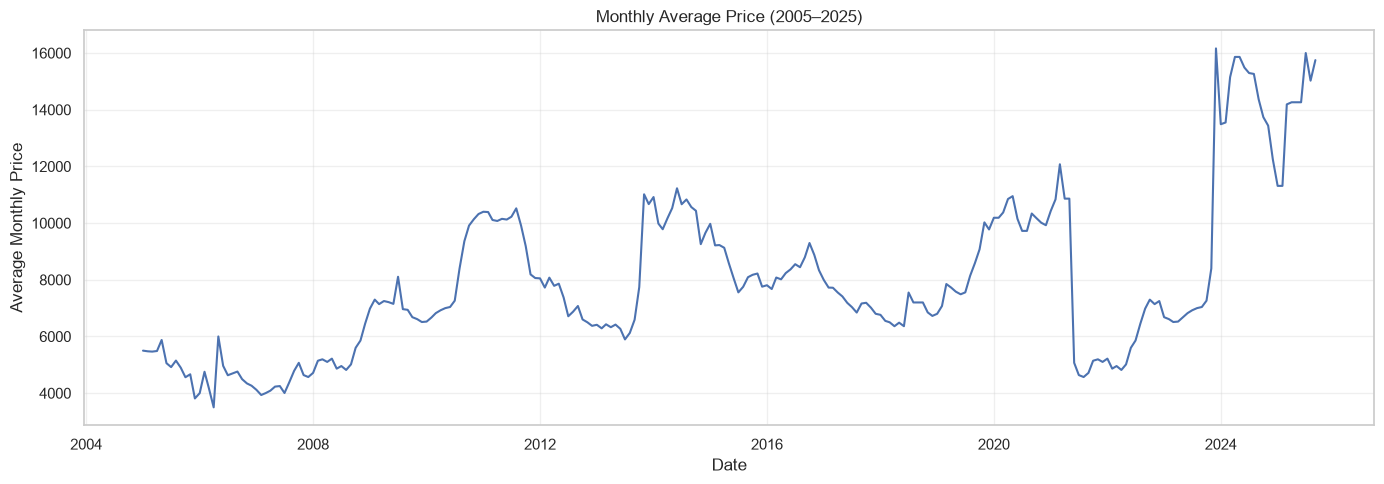

In [22]:
plt.figure(figsize=(14, 5))

plt.plot(df["date"], df["avg_monthly_price"], linewidth=1.5)

plt.title("Monthly Average Price (2005–2025)")
plt.xlabel("Date")
plt.ylabel("Average Monthly Price")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

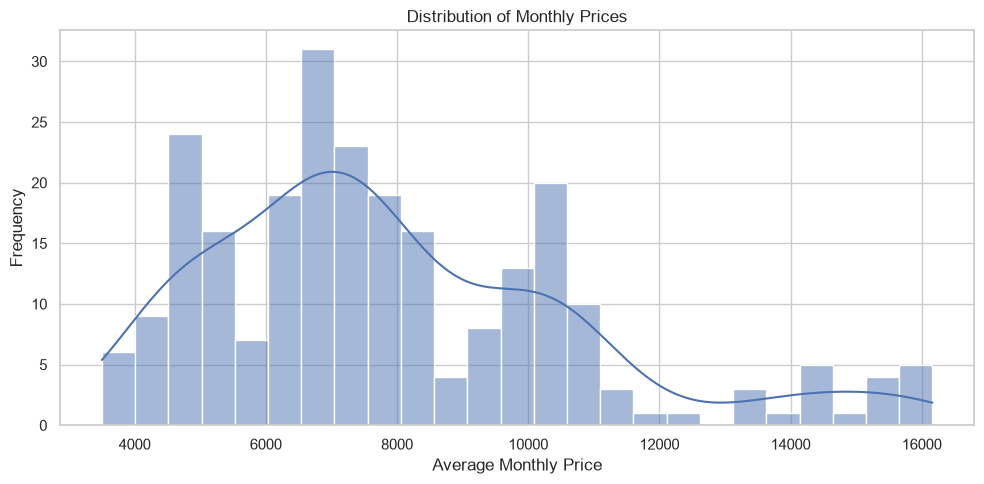

In [23]:
# checking price dist
plt.figure(figsize=(10, 5))

sns.histplot(df["avg_monthly_price"], bins=25, kde=True)

plt.title("Distribution of Monthly Prices")
plt.xlabel("Average Monthly Price")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [ ]:
# calculate yearly average
df["year"] = df["date"].dt.year

yearly_avg = df.groupby("year")["avg_monthly_price"].mean()

display(yearly_avg.round(2).to_frame("Average Price"))

,Average Price
year,
2005,5072.50
2006,4548.75
2007,4339.92
2008,5244.50
2009,7070.67
2010,8031.25
2011,9778.83
2012,7251.00
2013,7181.92


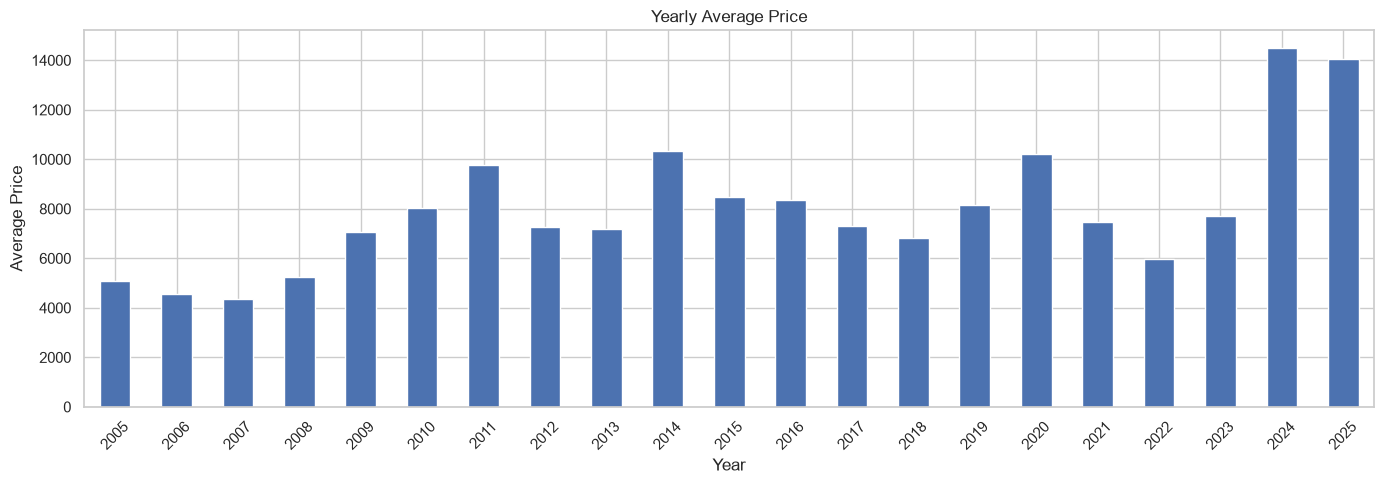

In [25]:
plt.figure(figsize=(14, 5))

yearly_avg.plot(kind="bar")

plt.title("Yearly Average Price")
plt.xlabel("Year")
plt.ylabel("Average Price")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [27]:
# calculate monthly pct change
df["monthly_change"] = df["avg_monthly_price"].pct_change() * 100

display(
    df[["date", "avg_monthly_price", "monthly_change"]].tail(15)
)

,date,avg_monthly_price,monthly_change
234,2024-07-01,15294,-1.252583
235,2024-08-01,15263,-0.202694
236,2024-09-01,14363,-5.896613
237,2024-10-01,13738,-4.351459
238,2024-11-01,13438,-2.183724
239,2024-12-01,12250,-8.840601
240,2025-01-01,11313,-7.648980
241,2025-02-01,11313,0.000000
242,2025-03-01,14188,25.413241
243,2025-04-01,14263,0.528616


- Don't remove any outliers yet.


### EDA Observations:
- Prices generally increased between 2005 and 2025, but there are periods of decline.
- noticeable changes around 2011, 2014, 2021 and 2024.
- The histogram is right-skewed, with a smaller number of observations at higher price levels.
- March 2025 recorded a 25.41% increase, while July 2025 recorded a 12.18% increase.
- 2025 contains only January–September data, so its yearly average is not directly comparable with complete years.
- Further analysis is required.

## Outlier and anomaly analysis


In [28]:
change_stats = df["monthly_change"].dropna()

median_change = change_stats.median()
mad = (change_stats - median_change).abs().median()

if mad > 0:
    df["modified_z_score"] = (
        0.6745 * (df["monthly_change"] - median_change) / mad
    )
else:
    df["modified_z_score"] = np.nan

df["anomaly_flag"] = df["modified_z_score"].abs() > 3.5

print("Median monthly change:", round(median_change, 2))
print("MAD:", round(mad, 2))
print("Potential anomalies:", df["anomaly_flag"].sum())

display(
    df.loc[
        df["anomaly_flag"],
        ["date", "avg_monthly_price", "monthly_change", "modified_z_score"]
    ]
)

Median monthly change: 0.0
MAD: 2.9
Potential anomalies: 14


,date,avg_monthly_price,monthly_change,modified_z_score
11,2005-12-01,3813,-18.263666,-4.252146
13,2006-02-01,4755,18.875000,4.394477
15,2006-04-01,3500,-16.187739,-3.768829
16,2006-05-01,6000,71.428571,16.629998
17,2006-06-01,4964,-17.266667,-4.020025
67,2010-08-01,8400,15.670614,3.648432
105,2013-10-01,7744,17.511381,4.076999
106,2013-11-01,11016,42.252066,9.837125
162,2018-07-01,7550,18.673373,4.347534
197,2021-06-01,5070,-53.327810,-12.415779


- Modified Z-score uses the median and median absolute deviation, making it less sensitive to extreme changes than a standard Z-score
- some large movements are followed by movements in the opposite direction. This may indicate temporary price shocks

In [29]:
largest_changes = df.loc[
    df["monthly_change"].abs().nlargest(10).index,
    ["date", "avg_monthly_price", "monthly_change"]
].sort_values("monthly_change", key=abs, ascending=False)

display(largest_changes)

,date,avg_monthly_price,monthly_change
227,2023-12-01,16163,92.416667
16,2006-05-01,6000,71.428571
197,2021-06-01,5070,-53.327810
106,2013-11-01,11016,42.252066
242,2025-03-01,14188,25.413241
13,2006-02-01,4755,18.875000
162,2018-07-01,7550,18.673373
11,2005-12-01,3813,-18.263666
105,2013-10-01,7744,17.511381
17,2006-06-01,4964,-17.266667


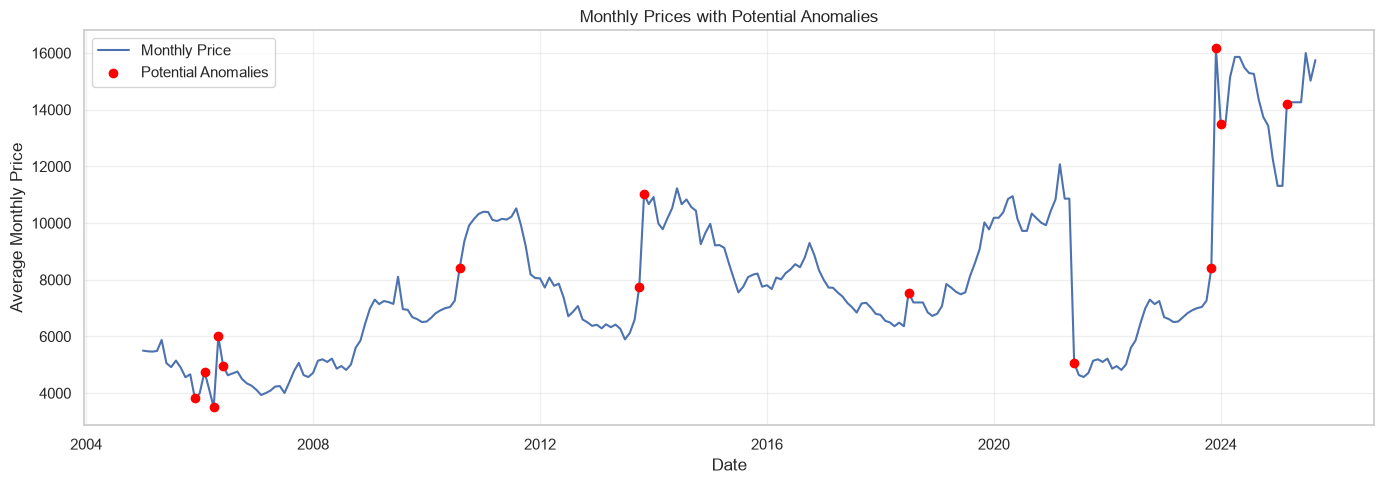

In [30]:
plt.figure(figsize=(14, 5))

plt.plot(
    df["date"],
    df["avg_monthly_price"],
    label="Monthly Price"
)

anomalies = df[df["anomaly_flag"]]

plt.scatter(
    anomalies["date"],
    anomalies["avg_monthly_price"],
    color="red",
    label="Potential Anomalies",
    zorder=3
)

plt.title("Monthly Prices with Potential Anomalies")
plt.xlabel("Date")
plt.ylabel("Average Monthly Price")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Anomaly Analysis

- 14 potential anomalies were identified using the Modified Z-score method.
- Major price movements occurred in 2006, 2013, 2021, 2023 and 2025.
- Some sharp movements were followed by reversals.
- All original observations are retained for forecasting.

## Time-series preparation

In [31]:
# creating time series
ts = df.set_index("date")["avg_monthly_price"].asfreq("MS")

print("Time series created.")
print("Frequency:", ts.index.freq)
print("Observations:", len(ts))
print("Missing values:", ts.isna().sum())

display(ts.head())
display(ts.tail())

Time series created.
Frequency: <MonthBegin>
Observations: 249
Missing values: 0


date
2005-01-01    5500
2005-02-01    5476
2005-03-01    5466
2005-04-01    5487
2005-05-01    5876
Freq: MS, Name: avg_monthly_price, dtype: int64

date
2025-05-01    14263
2025-06-01    14263
2025-07-01    16000
2025-08-01    15025
2025-09-01    15750
Freq: MS, Name: avg_monthly_price, dtype: int64

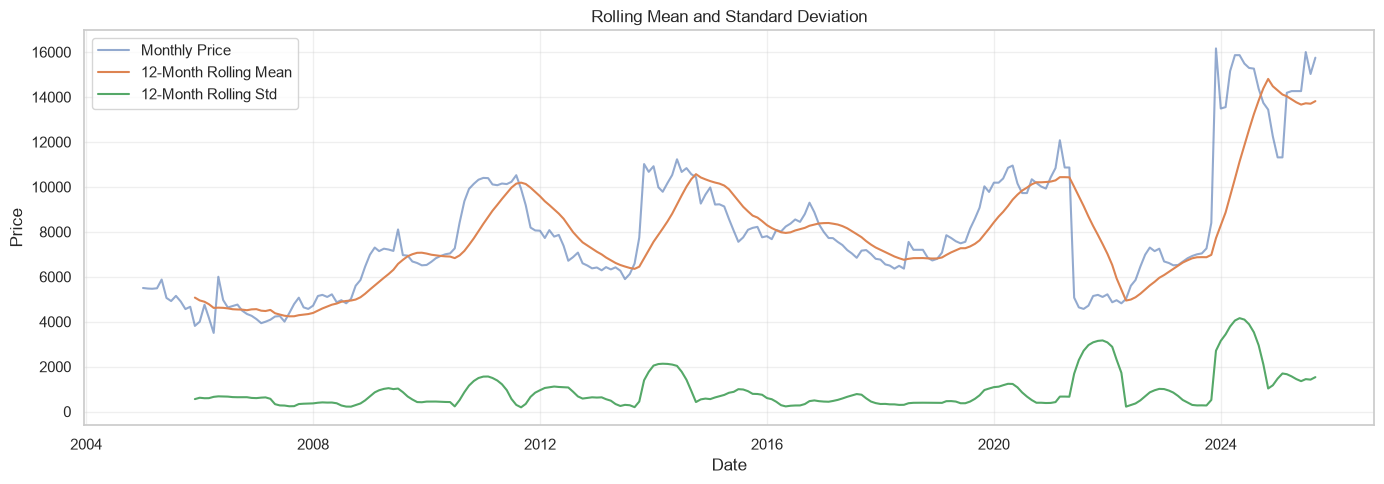

In [ ]:
# rolling mean and standard deviation
rolling_mean = ts.rolling(window=12).mean()
rolling_std = ts.rolling(window=12).std()

plt.figure(figsize=(14, 5))

plt.plot(ts, label="Monthly Price", alpha=0.6)
plt.plot(rolling_mean, label="12-Month Rolling Mean")
plt.plot(rolling_std, label="12-Month Rolling Std")

plt.title("Rolling Mean and Standard Deviation")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [33]:
# monthly seasonality
monthly_avg = df.groupby(
    df["date"].dt.month
)["avg_monthly_price"].mean()

display(monthly_avg.round(2).to_frame("Average Price"))

,Average Price
date,
1,7822.48
2,7774.67
3,8086.86
4,8032.43
5,8210.24
6,7770.19
7,7812.67
8,7865.52
9,8044.38


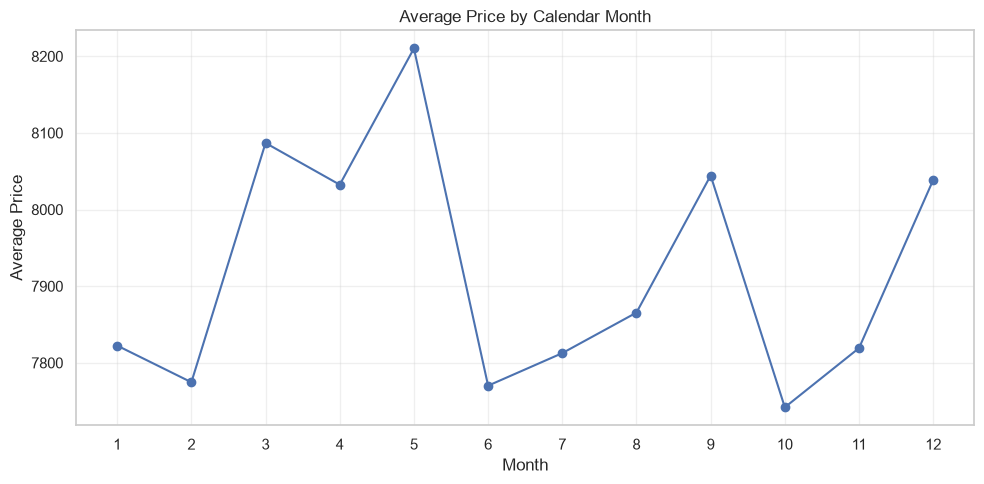

In [34]:
plt.figure(figsize=(10, 5))

monthly_avg.plot(marker="o")

plt.title("Average Price by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Average Price")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [35]:
train = ts.iloc[:-12]
test = ts.iloc[-12:]

print("Training period:", train.index.min(), "to", train.index.max())
print("Training records:", len(train))

print("\nTesting period:", test.index.min(), "to", test.index.max())
print("Testing records:", len(test))

Training period: 2005-01-01 00:00:00 to 2024-09-01 00:00:00
Training records: 237

Testing period: 2024-10-01 00:00:00 to 2025-09-01 00:00:00
Testing records: 12


### Time Series Observations

- The series shows an overall upward trend.
- Price variability changes over time.
- Monthly averages show some seasonal differences.
- Training data contains 237 observations.
- Testing data contains the final 12 observations.

## Time-series decomposition and stationarity

In [36]:
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

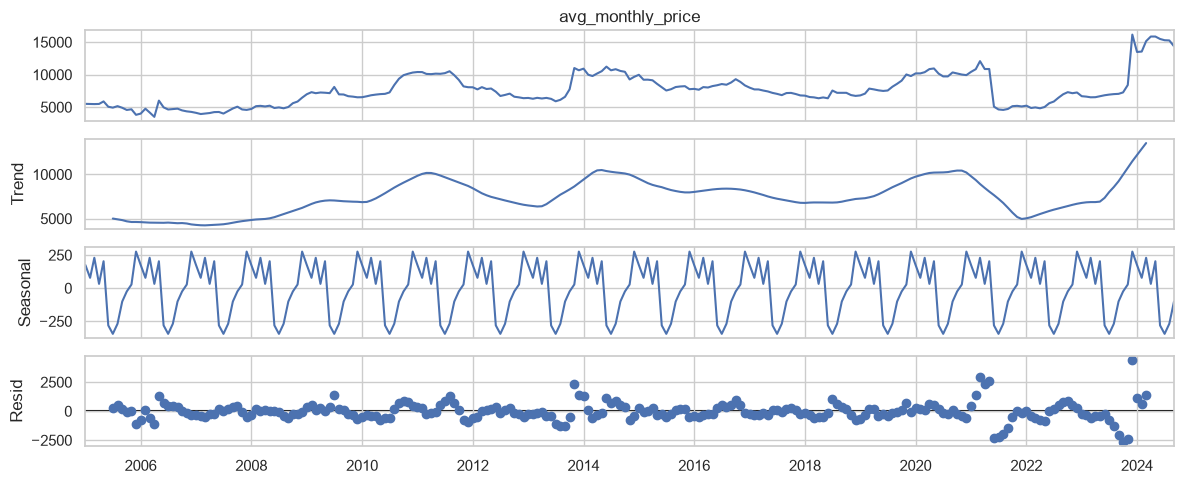

In [37]:
decomposition = seasonal_decompose(
    train,
    model="additive",
    period=12
)

decomposition.plot()
plt.tight_layout()
plt.show()

- Trend: long-term price movement.
- Seasonal: repeating annual pattern.
- Residual: remaining unexplained variation

In [38]:
adf_result = adfuller(train)

print("ADF Statistic:", round(adf_result[0], 4))
print("p-value:", round(adf_result[1], 4))

if adf_result[1] <= 0.05:
    print("The series is stationary.")
else:
    print("The series is non-stationary.")

ADF Statistic: -1.898
p-value: 0.333
The series is non-stationary.


- require differencing when the series is non-stationary

In [39]:
train_diff = train.diff().dropna()

adf_diff = adfuller(train_diff)

print("ADF Statistic:", round(adf_diff[0], 4))
print("p-value:", round(adf_diff[1], 4))

if adf_diff[1] <= 0.05:
    print("Differenced series is stationary.")
else:
    print("Differenced series is non-stationary.")

ADF Statistic: -15.7668
p-value: 0.0
Differenced series is stationary.


|Test|Result|Interpretation|
|---|---|---|
|Original ADF p-value|0.333|Non-stationary|
|First-differenced ADF p-value|0.000|Stationary|

### Stationarity and Decomposition

- The original series is non-stationary.
- First-order differencing makes the series stationary.
- The decomposition shows a changing trend and repeating seasonal component.
- ARIMA models with d=1 will be considered.

## Forecasting Models

### Baseline Models

Naive, Seasonal Naive, Moving Average and Drift models are used as benchmarks.

In [40]:
# Baseline forecasts

horizon = len(test)

forecasts = {}

# Naive
forecasts["Naive"] = np.repeat(train.iloc[-1], horizon)

# Seasonal Naive
forecasts["Seasonal Naive"] = np.tile(
    train.iloc[-12:].values,
    int(np.ceil(horizon / 12))
)[:horizon]

# Moving Average - 3 months
forecasts["MA3"] = np.repeat(train.iloc[-3:].mean(), horizon)

# Moving Average - 6 months
forecasts["MA6"] = np.repeat(train.iloc[-6:].mean(), horizon)

# Drift
drift = (train.iloc[-1] - train.iloc[0]) / (len(train) - 1)

forecasts["Drift"] = (
    train.iloc[-1] + drift * np.arange(1, horizon + 1)
)

print("Baseline forecasts generated.")

Baseline forecasts generated.


- Naive: uses the latest observed price for every forecast month.
- Seasonal Naive: repeats the prices from the previous 12 months.
- MA3 and MA6: use the average of the latest three or six months.
- Drift: extends the average historical direction of change.

In [41]:
# Calculate forecast errors
def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    mae = np.mean(np.abs(actual - predicted))
    rmse = np.sqrt(np.mean((actual - predicted) ** 2))

    smape = np.mean(
        200 * np.abs(actual - predicted) /
        (np.abs(actual) + np.abs(predicted))
    )

    return {
        "MAE": mae,
        "RMSE": rmse,
        "sMAPE": smape
    }


baseline_results = []

for model_name, prediction in forecasts.items():
    metrics = calculate_metrics(test.values, prediction)

    baseline_results.append({
        "Model": model_name,
        **metrics
    })

baseline_metrics = pd.DataFrame(baseline_results)
baseline_metrics = baseline_metrics.sort_values("MAE")

display(baseline_metrics.round(2))

,Model,MAE,RMSE,sMAPE
0,Naive,1160.33,1565.74,8.53
4,Drift,1197.89,1588.80,8.79
2,MA3,1465.50,1868.30,10.59
3,MA6,1711.78,2126.24,12.20
1,Seasonal Naive,2296.42,2921.06,18.52


- sMAPE: percentage-based forecast error
- Naive is currently the best baseline model. It performs slightly better than Drift on all three metrics

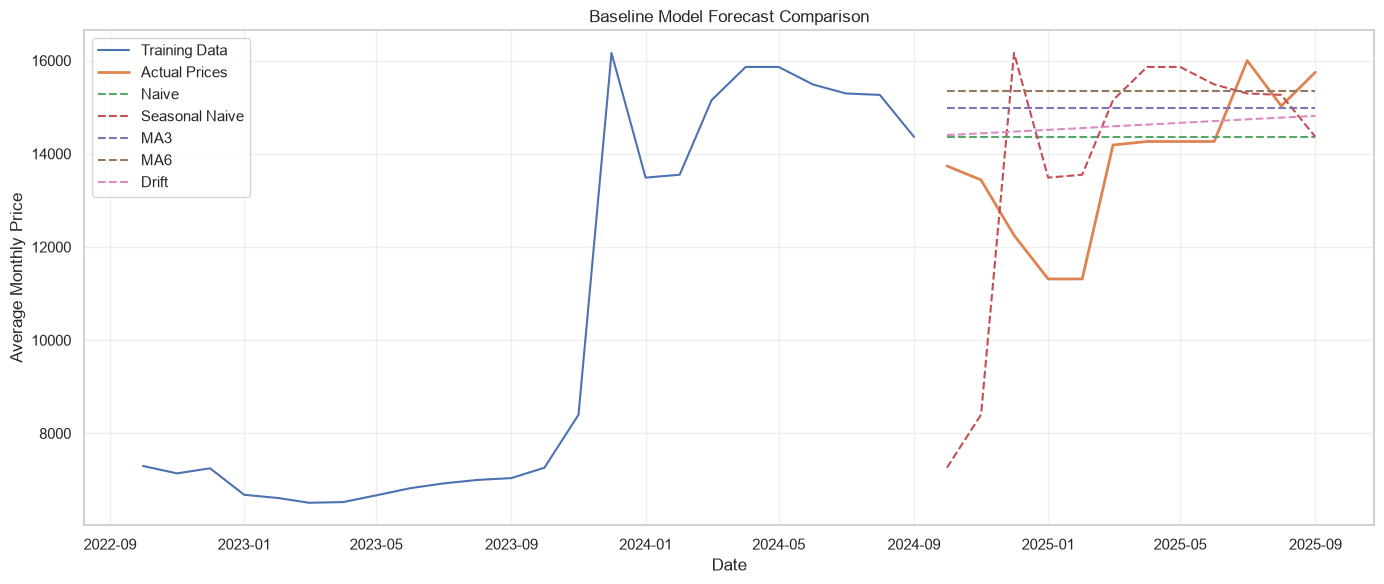

In [44]:
plt.figure(figsize=(14, 6))

plt.plot(train.tail(24), label="Training Data")
plt.plot(test, label="Actual Prices", linewidth=2)

for model_name, prediction in forecasts.items():
    plt.plot(
        test.index,
        prediction,
        linestyle="--",
        label=model_name
    )

plt.title("Baseline Model Forecast Comparison")
plt.xlabel("Date")
plt.ylabel("Average Monthly Price")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Advanced forecasting models

In [46]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

In [47]:
ets_model = ExponentialSmoothing(
    train,
    trend="add",
    damped_trend=True,
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
).fit()

ets_forecast = ets_model.forecast(12)

forecasts["ETS"] = ets_forecast.values

display(ets_forecast)

2024-10-01    14419.646173
2024-11-01    14367.901331
2024-12-01    14567.185037
2025-01-01    14451.135134
2025-02-01    14365.435760
2025-03-01    14573.401023
2025-04-01    14521.067346
2025-05-01    14720.085266
2025-06-01    14281.387674
2025-07-01    14250.668730
2025-08-01    14317.685508
2025-09-01    14365.793486
Freq: MS, dtype: float64

In [48]:
sarima_model = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fit = sarima_model.fit(disp=False)

sarima_forecast = sarima_fit.forecast(steps=12)

forecasts["SARIMA"] = sarima_forecast.values

display(sarima_forecast)

2024-10-01    14688.166300
2024-11-01    14681.328043
2024-12-01    15287.891359
2025-01-01    15047.170614
2025-02-01    15065.191301
2025-03-01    15318.715749
2025-04-01    15308.129056
2025-05-01    15335.791322
2025-06-01    14723.573967
2025-07-01    14654.987518
2025-08-01    14816.360197
2025-09-01    14946.431862
Freq: MS, Name: predicted_mean, dtype: float64

In [49]:
all_results = []

for model_name, prediction in forecasts.items():
    metrics = calculate_metrics(test.values, prediction)

    all_results.append({
        "Model": model_name,
        **metrics
    })

all_metrics = pd.DataFrame(all_results)

all_metrics = all_metrics.sort_values("MAE").reset_index(drop=True)

display(all_metrics.round(2))

,Model,MAE,RMSE,sMAPE
0,Naive,1160.33,1565.74,8.53
1,Drift,1197.89,1588.80,8.79
2,ETS,1256.59,1626.98,9.19
3,MA3,1465.50,1868.30,10.59
4,SARIMA,1565.35,1956.45,11.25
5,MA6,1711.78,2126.24,12.20
6,Seasonal Naive,2296.42,2921.06,18.52


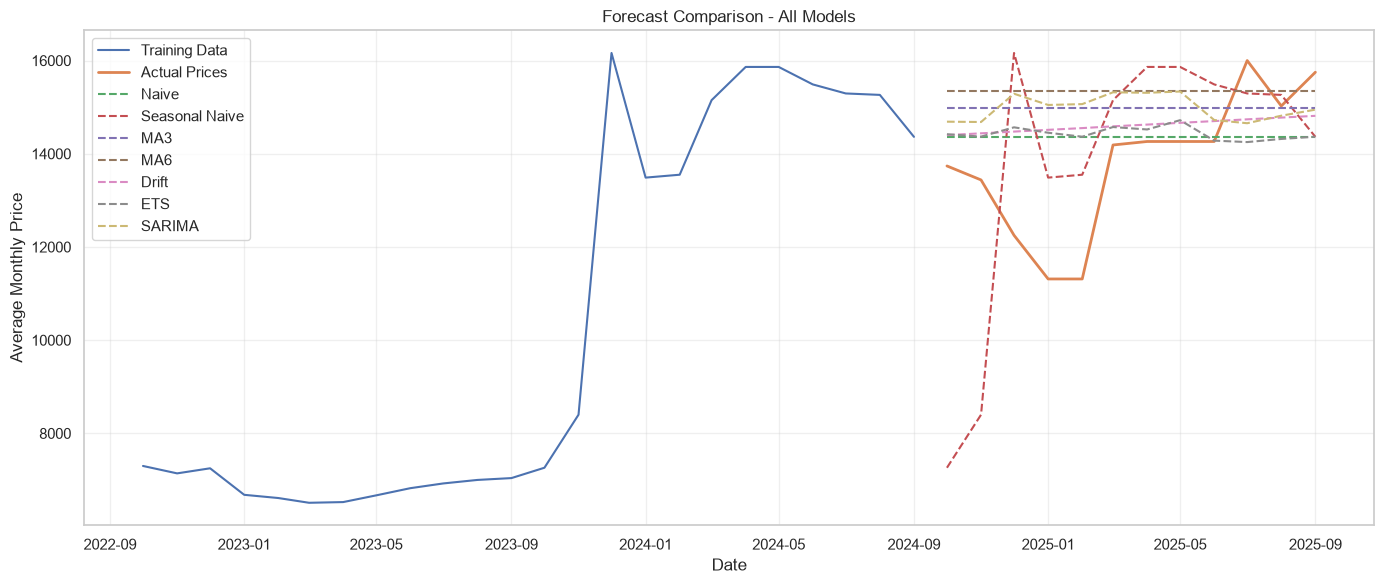

In [50]:
plt.figure(figsize=(14, 6))

plt.plot(train.tail(24), label="Training Data")
plt.plot(test, label="Actual Prices", linewidth=2)

for model_name, prediction in forecasts.items():
    plt.plot(
        test.index,
        prediction,
        linestyle="--",
        label=model_name
    )

plt.title("Forecast Comparison - All Models")
plt.xlabel("Date")
plt.ylabel("Average Monthly Price")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

- Naive currently performs best.
- Drift and ETS are reasonably close to Naive.
- SARIMA is not outperforming the simpler models.

## Feature Engineering

In [51]:
ml_data = pd.DataFrame(index=ts.index)

ml_data["price"] = ts

# Calendar features
ml_data["month"] = ml_data.index.month
ml_data["year"] = ml_data.index.year

# Lag features
for lag in [1, 2, 3, 6, 12]:
    ml_data[f"lag_{lag}"] = ml_data["price"].shift(lag)

# Rolling features using previous months only
for window in [3, 6, 12]:
    ml_data[f"rolling_mean_{window}"] = (
        ml_data["price"].shift(1).rolling(window).mean()
    )

ml_data["rolling_std_3"] = (
    ml_data["price"].shift(1).rolling(3).std()
)

ml_data = ml_data.dropna()

display(ml_data.head())
print("Feature dataset shape:", ml_data.shape)

,price,month,year,lag_1,lag_2,lag_3,lag_6,lag_12,rolling_mean_3,rolling_mean_6,rolling_mean_12,rolling_std_3
date,,,,,,,,,,,,
2006-01-01,4000,1,2006,3813.0,4665.0,4562.0,4919.0,5500.0,4346.666667,4667.833333,5072.500000,465.029390
2006-02-01,4755,2,2006,4000.0,3813.0,4665.0,5149.0,5476.0,4159.333333,4514.666667,4947.500000,447.790502
2006-03-01,4176,3,2006,4755.0,4000.0,3813.0,4899.0,5466.0,4189.333333,4449.000000,4887.416667,498.724707
2006-04-01,3500,4,2006,4176.0,4755.0,4000.0,4562.0,5487.0,4310.333333,4328.500000,4779.916667,395.019409
2006-05-01,6000,5,2006,3500.0,4176.0,4755.0,4665.0,5876.0,4143.666667,4151.500000,4614.333333,628.124457


Feature dataset shape: (237, 12)


In [52]:
X = ml_data.drop(columns=["price"])
y = ml_data["price"]

X_train = X.loc[train.index.intersection(X.index)]
y_train = y.loc[X_train.index]

X_test = X.loc[test.index.intersection(X.index)]
y_test = y.loc[X_test.index]

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training period:", X_train.index.min(), "to", X_train.index.max())
print("Testing period:", X_test.index.min(), "to", X_test.index.max())

Training features: (225, 11)
Testing features: (12, 11)
Training period: 2006-01-01 00:00:00 to 2024-09-01 00:00:00
Testing period: 2024-10-01 00:00:00 to 2025-09-01 00:00:00


In [55]:
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

In [56]:
def create_future_features(history, date):
    features = {
        "month": date.month,
        "year": date.year
    }

    for lag in [1, 2, 3, 6, 12]:
        features[f"lag_{lag}"] = history.iloc[-lag]

    for window in [3, 6, 12]:
        features[f"rolling_mean_{window}"] = (
            history.iloc[-window:].mean()
        )

    features["rolling_std_3"] = history.iloc[-3:].std()

    return pd.DataFrame([features])

In [57]:
def recursive_forecast(model, history, forecast_dates):
    history = history.copy()
    predictions = []

    for date in forecast_dates:
        X_future = create_future_features(history, date)

        prediction = model.predict(X_future)[0]

        predictions.append(prediction)

        history.loc[date] = prediction

    return np.array(predictions)

In [59]:
# train Random forest
rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=5,
    min_samples_split=5,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_forecast = recursive_forecast(
    rf_model,
    train,
    test.index
)

forecasts["Random Forest"] = rf_forecast

print("Random Forest training completed.")

Random Forest training completed.


In [60]:
# train XGBoost
xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

xgb_model.fit(X_train, y_train)

xgb_forecast = recursive_forecast(
    xgb_model,
    train,
    test.index
)

forecasts["XGBoost"] = xgb_forecast

print("XGBoost training completed.")

XGBoost training completed.


In [61]:
# evaluate
ml_results = []

for name, prediction in {
    "Random Forest": rf_forecast,
    "XGBoost": xgb_forecast
}.items():

    metrics = calculate_metrics(test.values, prediction)

    ml_results.append({
        "Model": name,
        **metrics
    })

ml_metrics = pd.DataFrame(ml_results)

display(ml_metrics.round(2))

,Model,MAE,RMSE,sMAPE
0,Random Forest,1497.18,1845.10,10.80
1,XGBoost,1218.33,1524.24,8.92


In [62]:
all_results = []

for name, prediction in forecasts.items():
    metrics = calculate_metrics(test.values, prediction)

    all_results.append({
        "Model": name,
        **metrics
    })

all_metrics = pd.DataFrame(all_results)
all_metrics = all_metrics.sort_values("MAE").reset_index(drop=True)

display(all_metrics.round(2))

,Model,MAE,RMSE,sMAPE
0,Naive,1160.33,1565.74,8.53
1,Drift,1197.89,1588.80,8.79
2,XGBoost,1218.33,1524.24,8.92
3,ETS,1256.59,1626.98,9.19
4,MA3,1465.50,1868.30,10.59
5,Random Forest,1497.18,1845.10,10.80
6,SARIMA,1565.35,1956.45,11.25
7,MA6,1711.78,2126.24,12.20
8,Seasonal Naive,2296.42,2921.06,18.52


- Naive has the lowest MAE and sMAPE.
- Random Forest has not improved on the simpler models.

## Model Validation
Expanding Window-Backtesting

In [64]:
def prepare_ml_features(history):
    data = pd.DataFrame({"price": history})

    data["month"] = data.index.month
    data["year"] = data.index.year

    for lag in [1, 2, 3, 6, 12]:
        data[f"lag_{lag}"] = data["price"].shift(lag)

    for window in [3, 6, 12]:
        data[f"rolling_mean_{window}"] = (
            data["price"].shift(1).rolling(window).mean()
        )

    data["rolling_std_3"] = (
        data["price"].shift(1).rolling(3).std()
    )

    return data.dropna()

In [76]:
backtest_results = []
backtest_predictions = []

cutoff_dates = pd.date_range(
    start="2017-09-01", # sept 2017
    end="2023-09-01", # sept 2023
    freq="12MS"
)

for cutoff in cutoff_dates:

    cutoff_pos = ts.index.get_loc(cutoff)

    history = ts.iloc[:cutoff_pos + 1].copy()
    actual = ts.iloc[cutoff_pos + 1:cutoff_pos + 13]

    if len(actual) != 12:
        continue

    horizon = len(actual)
    predictions = {}

    # Baseline models
    predictions["Naive"] = np.repeat(history.iloc[-1], horizon)

    predictions["Seasonal Naive"] = np.tile(
        history.iloc[-12:].values, 1
    )

    predictions["MA3"] = np.repeat(history.iloc[-3:].mean(), horizon)
    predictions["MA6"] = np.repeat(history.iloc[-6:].mean(), horizon)

    drift = (
        (history.iloc[-1] - history.iloc[0]) /
        (len(history) - 1)
    )

    predictions["Drift"] = (
        history.iloc[-1] + drift * np.arange(1, horizon + 1)
    )

    # ETS
    ets = ExponentialSmoothing(
        history,
        trend="add",
        damped_trend=True,
        seasonal="add",
        seasonal_periods=12,
        initialization_method="estimated"
    ).fit()

    predictions["ETS"] = ets.forecast(horizon).values

    # SARIMA
    sarima = SARIMAX(
        history,
        order=(1, 1, 1),
        seasonal_order=(1, 1, 1, 12),
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit(disp=False)

    predictions["SARIMA"] = sarima.forecast(horizon).values

    # Machine learning features
    feature_data = prepare_ml_features(history)

    X_fold = feature_data.drop(columns=["price"])
    y_fold = feature_data["price"]

    rf = RandomForestRegressor(
        n_estimators=300,
        max_depth=5,
        min_samples_split=5,
        random_state=42
    )

    rf.fit(X_fold, y_fold)

    predictions["Random Forest"] = recursive_forecast(
        rf, history, actual.index
    )

    xgb = XGBRegressor(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42
    )

    xgb.fit(X_fold, y_fold)

    predictions["XGBoost"] = recursive_forecast(
        xgb, history, actual.index
    )

    # Evaluate each model
    for name, prediction in predictions.items():

        metrics = calculate_metrics(actual.values, prediction)

        backtest_results.append({
            "Cutoff": cutoff,
            "Model": name,
            **metrics
        })

        for date, actual_value, predicted_value in zip(
            actual.index, actual.values, prediction
        ):
            backtest_predictions.append({
                "Cutoff": cutoff,
                "Date": date,
                "Model": name,
                "Actual": actual_value,
                "Predicted": predicted_value,
                "Error": predicted_value - actual_value
            })

    print("Completed:", cutoff.strftime("%Y-%m"))

Completed: 2017-09
Completed: 2018-09
Completed: 2019-09
Completed: 2020-09
Completed: 2021-09
Completed: 2022-09
Completed: 2023-09


In [77]:
# calculate avg backtesting perf
backtest_df = pd.DataFrame(backtest_results)

backtest_summary = (
    backtest_df.groupby("Model")[["MAE", "RMSE", "sMAPE"]]
    .mean()
    .sort_values("MAE")
)

display(backtest_summary.round(2))

,MAE,RMSE,sMAPE
Model,,,
Drift,1764.08,2091.44,19.29
Naive,1773.93,2087.45,19.40
Random Forest,1805.50,2073.39,19.66
SARIMA,1845.38,2193.69,20.58
ETS,1855.52,2173.55,21.09
MA3,1879.03,2158.84,20.85
XGBoost,1998.88,2202.77,22.13
MA6,2147.32,2442.32,24.70
Seasonal Naive,2732.37,3109.21,32.20


- Drift has the lowest average MAE and sMAPE.
- Random Forest is competitive in backtesting
- The September 2023 cutoff produces large errors across all models

Keeping Naive and Drift as leading candidates

In [78]:
backtest_df.pivot(
    index="Cutoff",
    columns="Model",
    values="MAE"
).round(2) 

Model,Drift,ETS,MA3,MA6,Naive,Random Forest,SARIMA,Seasonal Naive,XGBoost
Cutoff,,,,,,,,,
2017-09-01,451.47,431.48,363.31,426.50,412.75,546.62,555.22,1081.42,1206.60
2018-09-01,448.20,557.96,470.22,638.75,489.67,469.68,564.21,673.08,462.34
2019-09-01,1411.62,1479.10,2019.67,2267.67,1525.67,1580.00,1484.07,2649.00,1565.18
2020-09-01,2260.84,2199.07,2206.36,2211.53,2219.58,2269.84,2252.99,2074.58,2049.62
2021-09-01,743.93,1153.90,792.75,1385.53,718.42,493.90,866.40,4230.00,479.74
2022-09-01,271.61,389.36,443.67,1086.00,245.83,774.79,452.90,1439.58,1664.35
2023-09-01,6760.90,6777.76,6857.25,7015.25,6805.58,6503.64,6741.85,6978.92,6564.35


In [79]:
# Pooled backtesting metrics
pooled_results = []

for model_name, group in backtest_df.groupby("Model"):

    actual = []
    predicted = []

    for cutoff in group["Cutoff"]:
        cutoff_pos = ts.index.get_loc(cutoff)

        history = ts.iloc[:cutoff_pos + 1]
        actual_values = ts.iloc[cutoff_pos + 1:cutoff_pos + 13]

        # Retrieve predictions from the corresponding fold
        # We will store predictions in the next backtesting run.

    pooled_results.append({
        "Model": model_name,
        "Mean Fold MAE": group["MAE"].mean(),
        "Mean Fold RMSE": group["RMSE"].mean(),
        "Mean Fold sMAPE": group["sMAPE"].mean()
    })

pooled_summary = pd.DataFrame(pooled_results)

display(pooled_summary.round(2))

,Model,Mean Fold MAE,Mean Fold RMSE,Mean Fold sMAPE
0,Drift,1764.08,2091.44,19.29
1,ETS,1855.52,2173.55,21.09
2,MA3,1879.03,2158.84,20.85
3,MA6,2147.32,2442.32,24.70
4,Naive,1773.93,2087.45,19.40
5,Random Forest,1805.50,2073.39,19.66
6,SARIMA,1845.38,2193.69,20.58
7,Seasonal Naive,2732.37,3109.21,32.20
8,XGBoost,1998.88,2202.77,22.13


In [80]:
# Calculate pooled metrics

prediction_df = pd.DataFrame(backtest_predictions)

pooled_results = []

for model_name, group in prediction_df.groupby("Model"):

    metrics = calculate_metrics(
        group["Actual"].values,
        group["Predicted"].values
    )

    pooled_results.append({
        "Model": model_name,
        **metrics
    })

pooled_metrics = pd.DataFrame(pooled_results)

pooled_metrics = pooled_metrics.sort_values("MAE")

display(pooled_metrics.round(2))

,Model,MAE,RMSE,sMAPE
0,Drift,1764.08,3144.67,19.29
4,Naive,1773.93,3145.28,19.40
5,Random Forest,1805.50,3011.65,19.66
6,SARIMA,1845.38,3163.91,20.58
1,ETS,1855.52,3164.03,21.09
2,MA3,1879.03,3177.87,20.85
8,XGBoost,1998.88,3044.49,22.13
3,MA6,2147.32,3329.65,24.70
7,Seasonal Naive,2732.37,3803.62,32.20


- Drift has the lowest pooled MAE and sMAPE, while Random Forest has the lowest pooled RMSE.

In [81]:
# Compare model consistency

consistency_metrics = (
    backtest_df.groupby("Model")["MAE"]
    .agg(
        Mean_MAE="mean",
        Median_MAE="median",
        Std_MAE="std",
        Best_MAE="min",
        Worst_MAE="max"
    )
)

consistency_metrics["MAE_Variation"] = (
    consistency_metrics["Std_MAE"] /
    consistency_metrics["Mean_MAE"] * 100
)

display(
    consistency_metrics.sort_values("Mean_MAE").round(2)
)

,Mean_MAE,Median_MAE,Std_MAE,Best_MAE,Worst_MAE,MAE_Variation
Model,,,,,,
Drift,1764.08,743.93,2311.63,271.61,6760.90,131.04
Naive,1773.93,718.42,2328.42,245.83,6805.58,131.26
Random Forest,1805.50,774.79,2179.10,469.68,6503.64,120.69
SARIMA,1845.38,866.40,2253.72,452.90,6741.85,122.13
ETS,1855.52,1153.90,2267.22,389.36,6777.76,122.19
MA3,1879.03,792.75,2324.94,363.31,6857.25,123.73
XGBoost,1998.88,1565.18,2099.31,462.34,6564.35,105.02
MA6,2147.32,1385.53,2260.50,426.50,7015.25,105.27
Seasonal Naive,2732.37,2074.58,2211.84,673.08,6978.92,80.95


In [82]:
# counting the best model in each fold
fold_winners = (
    backtest_df.loc[
        backtest_df.groupby("Cutoff")["MAE"].idxmin(),
        ["Cutoff", "Model", "MAE"]
    ]
    .sort_values("Cutoff")
)

display(fold_winners)

win_counts = (
    fold_winners["Model"]
    .value_counts()
    .rename("Fold Wins")
    .to_frame()
)

display(win_counts)

,Cutoff,Model,MAE
2,2017-09-01,MA3,363.305556
13,2018-09-01,Drift,448.203252
22,2019-09-01,Drift,1411.621212
35,2020-09-01,XGBoost,2049.622274
44,2021-09-01,XGBoost,479.736125
45,2022-09-01,Naive,245.833333
61,2023-09-01,Random Forest,6503.641040


,Fold Wins
Model,
Drift,2
XGBoost,2
MA3,1
Naive,1
Random Forest,1


- Drift and XGBoost tie on fold wins, but Drift has better average MAE.

In [83]:
# calculate forecast bias
bias_summary = (
    prediction_df.groupby("Model")["Error"]
    .agg(
        Mean_Bias="mean",
        Median_Bias="median"
    )
)

display(bias_summary.round(2))

,Mean_Bias,Median_Bias
Model,,
Drift,-961.70,-287.83
ETS,-1067.18,-490.62
MA3,-1261.33,-518.33
MA6,-1092.00,-661.83
Naive,-1030.90,-337.00
Random Forest,-900.46,-196.82
SARIMA,-987.77,-344.56
Seasonal Naive,-869.13,-1081.50
XGBoost,-772.47,-102.26


- Positive bias: model tends to overpredict.
- Negative bias: model tends to underpredict.
- Bias near zero: little average directional error.

This indicates systematic underprediction across these backtesting periods. This is particularly important for business decisions involving procurement budgets.

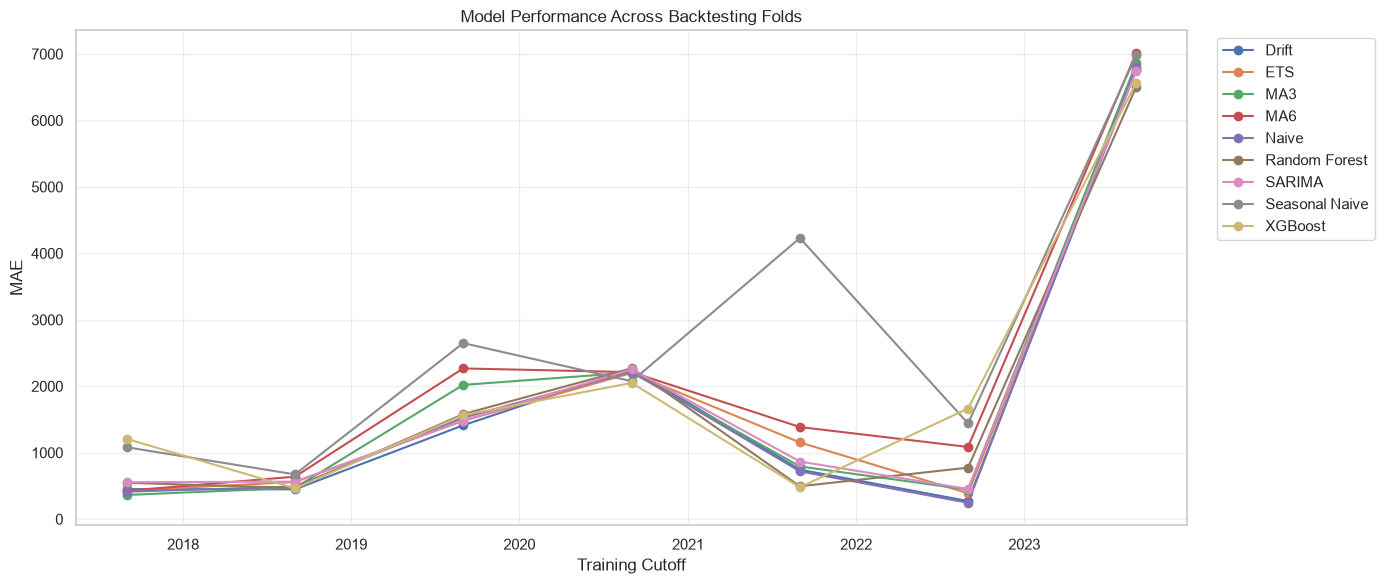

In [85]:
# Compare MAE across backtesting folds

mae_pivot = backtest_df.pivot(
    index="Cutoff",
    columns="Model",
    values="MAE"
)

plt.figure(figsize=(14, 6))

for model_name in mae_pivot.columns:
    plt.plot(
        mae_pivot.index,
        mae_pivot[model_name],
        marker="o",
        label=model_name
    )

plt.title("Model Performance Across Backtesting Folds")
plt.xlabel("Training Cutoff")
plt.ylabel("MAE")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [69]:
df.head()

,date,avg_monthly_price,year,monthly_change,modified_z_score,anomaly_flag
0,2005-01-01,5500,2005,NaN,NaN,False
1,2005-02-01,5476,2005,-0.436364,-0.101594,False
2,2005-03-01,5466,2005,-0.182615,-0.042516,False
3,2005-04-01,5487,2005,0.384193,0.089448,False
4,2005-05-01,5876,2005,7.089484,1.650574,False


## Final Price Forecast

Drift and Naive models are used to generate forecasts for the next 12 months

In [ ]:
# Generate the next 12 months oct 2025 to sep 2026
forecast_dates = pd.date_range(
    start=ts.index[-1] + pd.offsets.MonthBegin(1),
    periods=12,
    freq="MS"
)

# Naive forecast
final_naive = np.repeat(ts.iloc[-1], 12)

# Drift forecast
final_drift_rate = (
    (ts.iloc[-1] - ts.iloc[0]) / (len(ts) - 1)
)

final_drift = (
    ts.iloc[-1] +
    final_drift_rate * np.arange(1, 13)
)

final_forecast = pd.DataFrame({
    "Date": forecast_dates,
    "Naive Forecast": final_naive,
    "Drift Forecast": final_drift
})

display(final_forecast.round(2))

,Date,Naive Forecast,Drift Forecast
0,2025-10-01,15750,15791.33
1,2025-11-01,15750,15832.66
2,2025-12-01,15750,15873.99
3,2026-01-01,15750,15915.32
4,2026-02-01,15750,15956.65
5,2026-03-01,15750,15997.98
6,2026-04-01,15750,16039.31
7,2026-05-01,15750,16080.65
8,2026-06-01,15750,16121.98
9,2026-07-01,15750,16163.31


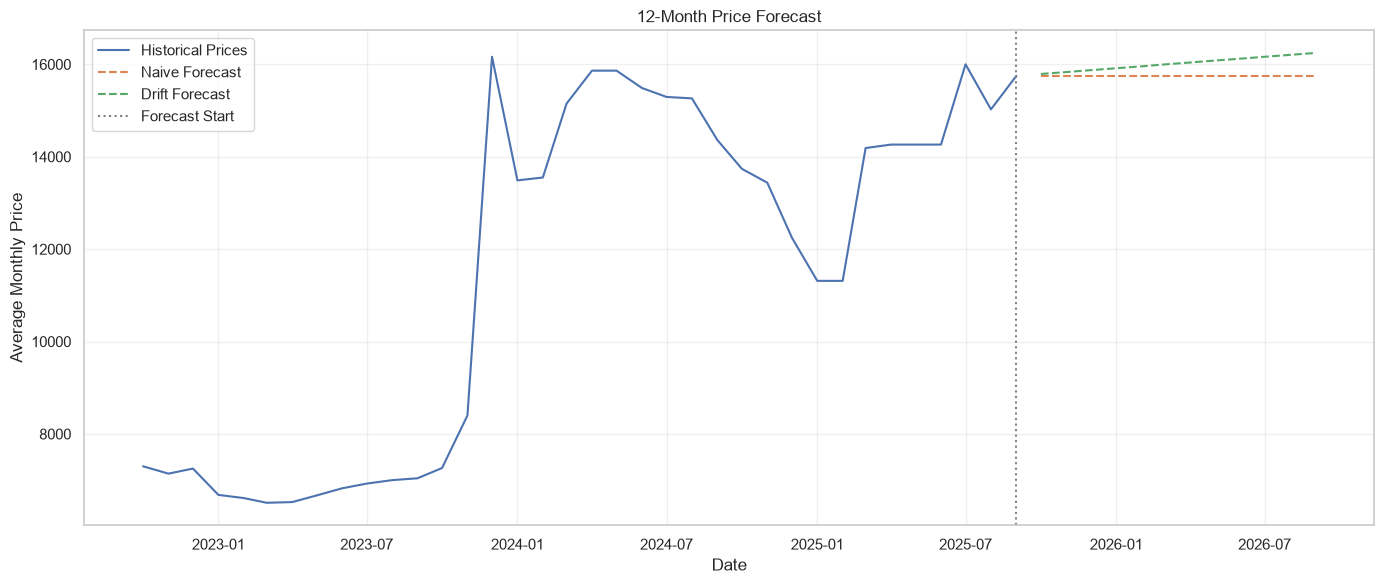

In [71]:
plt.figure(figsize=(14, 6))

plt.plot(
    ts.tail(36),
    label="Historical Prices"
)

plt.plot(
    forecast_dates,
    final_naive,
    linestyle="--",
    label="Naive Forecast"
)

plt.plot(
    forecast_dates,
    final_drift,
    linestyle="--",
    label="Drift Forecast"
)

plt.axvline(
    ts.index[-1],
    color="gray",
    linestyle=":",
    label="Forecast Start"
)

plt.title("12-Month Price Forecast")
plt.xlabel("Date")
plt.ylabel("Average Monthly Price")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

- The Drift model projects a gradual increase, while Naive assumes the latest price remains unchanged.

In [72]:
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

forecast_path = OUTPUT_DIR / "12_month_price_forecast.csv"

final_forecast.to_csv(forecast_path, index=False)

print("Forecast saved:", forecast_path)

Forecast saved: d:\BECAME_DEVELOPER\PriceForecastingW2A\outputs\12_month_price_forecast.csv


## Business insights and recommendations

In [73]:
# forecast changes
final_forecast["Drift Change"] = (
    final_forecast["Drift Forecast"].diff()
)

final_forecast["Drift Change %"] = (
    final_forecast["Drift Forecast"].pct_change() * 100
)

display(final_forecast.round(2))

,Date,Naive Forecast,Drift Forecast,Drift Change,Drift Change %
0,2025-10-01,15750,15791.33,NaN,NaN
1,2025-11-01,15750,15832.66,41.33,0.26
2,2025-12-01,15750,15873.99,41.33,0.26
3,2026-01-01,15750,15915.32,41.33,0.26
4,2026-02-01,15750,15956.65,41.33,0.26
5,2026-03-01,15750,15997.98,41.33,0.26
6,2026-04-01,15750,16039.31,41.33,0.26
7,2026-05-01,15750,16080.65,41.33,0.26
8,2026-06-01,15750,16121.98,41.33,0.26
9,2026-07-01,15750,16163.31,41.33,0.26
